# IMPORATION DES BIBLIOTHEQUES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
import plotly.express as px
import plotly.figure_factory as ff
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
import pyfixest as pf
from itertools import combinations
import warnings
warnings.filterwarnings("ignore", message=".*singleton fixed effect.*")

In [26]:
# =====================================================================
#  STYLE COMMUN
# =====================================================================
COULEURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
            "#e87ba4", "#008300", "#6250d6", "#e34948"]       # 8 couleurs maximum
BLEU_SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
TEXTE, TEXTE2, GRILLE = "#0b0b0b", "#52514e", "#e6e5e1"

pio.templates["memoire"] = go.layout.Template(layout=dict(
    font=dict(family="Arial, sans-serif", size=13, color=TEXTE),
    paper_bgcolor="white", plot_bgcolor="white", colorway=COULEURS,
    separators=", ",
    title=dict(x=0, xanchor="left", font=dict(size=16)),
    xaxis=dict(showgrid=False, zeroline=False, linecolor=TEXTE2, ticks="outside",
               tickcolor=TEXTE2, title=dict(font=dict(size=12, color=TEXTE2))),
    yaxis=dict(gridcolor=GRILLE, zeroline=False, showline=False,
               title=dict(font=dict(size=12, color=TEXTE2))),
    legend=dict(orientation="h", x=0, y=1.08, title=None, font=dict(size=12)),
    margin=dict(l=110, r=40, t=90, b=110),
    width=900, height=500, bargap=0.35,
))
pio.templates.default = "memoire"


# =====================================================================
#  OUTILS INTERNES
# =====================================================================
def _liste(v, defaut=None):
    """'a' -> ['a'] ; None -> defaut ; liste -> liste."""
    if v is None:
        return defaut
    return [v] if isinstance(v, str) else list(v)

def _a_plat(df):
    """Accepte un DataFrame/Series, avec ou sans index nommé (ex. par_sem)."""
    if isinstance(df, pd.Series):
        df = df.to_frame()
    return df.reset_index() if any(n is not None for n in df.index.names) else df.copy()

def _verifier_couleurs(n):
    if n > len(COULEURS):
        raise ValueError(f"{n} séries sur un même graphique : maximum {len(COULEURS)}. "
                         "Réduisez la liste, ou utilisez petits_multiples().")

def finir(fig, titre, source="Spotify Charts ; calculs de l'auteur", note=None):
    fig.update_layout(title_text=titre)
    texte = f"Source : {source}." + (f" {note}" if note else "")
    fig.add_annotation(text=texte, xref="paper", yref="paper", x=0, y=0, yshift=-78,
                       showarrow=False, xanchor="left", yanchor="top",
                       font=dict(size=11, color=TEXTE2))
    return fig


# =====================================================================
#  1. COURBES DANS LE TEMPS
#     - par="pays"    : un graphique par pays, une courbe par colonne
#     - par="colonne" : un graphique par colonne, une courbe par pays
# =====================================================================



# =====================================================================
#  2. PETITS GRAPHIQUES (un panneau par pays, mêmes échelles)
# =====================================================================
def petits_multiples(df, colonnes, pays=None, x="semaine", pays_col="pays", ncols=5,
                     titre="", axe="", noms=None, ymin=0, show=True, **kw):
    d = _a_plat(df)
    colonnes = _liste(colonnes)
    pays = _liste(pays, list(d[pays_col].unique()))
    noms = noms or {}
    _verifier_couleurs(len(colonnes))
    d = d[d[pays_col].isin(pays)].sort_values(x)
    lignes = -(-len(pays) // ncols)
    fig = make_subplots(rows=lignes, cols=min(ncols, len(pays)), subplot_titles=pays,
                        shared_xaxes=True, shared_yaxes="all",
                        horizontal_spacing=0.03, vertical_spacing=0.12)
    for k, p in enumerate(pays):
        dd = d[d[pays_col] == p]
        for i, c in enumerate(colonnes):
            fig.add_scatter(x=dd[x], y=dd[c], mode="lines", name=noms.get(c, c),
                            line=dict(color=COULEURS[i], width=1.8),
                            showlegend=(k == 0 and len(colonnes) > 1), legendgroup=c,
                            row=k // ncols + 1, col=k % ncols + 1)
    fig.update_annotations(font=dict(size=12, color=TEXTE))
    fig.update_xaxes(tickangle=0, nticks=3, tickformat="%Y")

    if ymin is not None:
        fig.update_yaxes(rangemode="tozero")
    haut = 220 * lignes + 150
    fig.update_layout(height=haut, margin=dict(l=70, r=30, t=110, b=110))
    if len(colonnes) > 1:       # légende en haut à droite, au-dessus des titres de panneaux
        fig.update_layout(legend=dict(orientation="h", x=1, xanchor="right",
                                      y=1 + 75 / (haut - 220), yanchor="bottom"))
    fig = finir(fig, (titre + (f"<br><sup>{axe}</sup>" if axe else "")), **kw)
    if show:
        fig.show()
    return fig


# =====================================================================
#  3. BARRES : une ou plusieurs colonnes, un ou plusieurs pays
# =====================================================================
def barres(df, colonnes, pays=None, pays_col="pays", titre="", axe="", noms=None,
           trier_par=None, format_val=",.0f", valeurs=None, empiler=False, total=None,
           show=True, **kw):
    """df : tableau avec un pays par ligne (dans la colonne pays ou dans l'index).
    colonnes   : colonne(s) à représenter.
    empiler    : False = barres côte à côte ; True = barres empilées (parties d'un total).
    total      : (avec empiler) colonne du total, affichée au bout de chaque barre.
    trier_par  : colonne servant au tri (par défaut la première ; peut être le total).
    valeurs    : afficher les chiffres (par défaut : oui si une seule colonne ou empilé)."""
    if isinstance(df, pd.Series):
        df = df.to_frame()
    d = df.set_index(pays_col) if pays_col in df.columns else df.copy()
    colonnes = _liste(colonnes)
    noms = noms or {}
    _verifier_couleurs(len(colonnes))
    if pays is not None:
        d = d.loc[_liste(pays)]
    d = d.sort_values(trier_par or (total if (empiler and total) else colonnes[0]))
    valeurs = (len(colonnes) == 1 or empiler) if valeurs is None else valeurs
    fig = go.Figure()
    for i, c in enumerate(colonnes):
        fig.add_bar(y=d.index, x=d[c], orientation="h", name=noms.get(c, c),
                    marker=dict(color=COULEURS[i],
                                line=dict(color="white", width=2 if empiler else 0)),
                    text=d[c] if valeurs else None,
                    texttemplate="%{text:" + format_val + "}" if valeurs else None,
                    textposition="inside" if empiler else "outside",
                    insidetextanchor="middle",
                    textfont=dict(color="white", size=12) if empiler else None,
                    cliponaxis=False)
    if empiler and total:
        fig.add_scatter(x=d[total], y=d.index, mode="text", text=d[total],
                        texttemplate="  %{text:" + format_val + "}", textposition="middle right",
                        textfont=dict(color=TEXTE, size=13), showlegend=False,
                        hoverinfo="skip", cliponaxis=False)
        fig.update_xaxes(range=[0, d[total].max() * 1.12])
    fig.update_xaxes(title_text=axe, showgrid=True, gridcolor=GRILLE, ticks="")
    fig.update_yaxes(showgrid=False, ticks="")
    fig.update_layout(barmode="stack" if empiler else "group", showlegend=len(colonnes) > 1,
                      legend=dict(orientation="h", x=0, y=1.14, traceorder="normal"),
                      height=max(320, 190 + 26 * len(d) * (1 if empiler else len(colonnes))))
    fig = finir(fig, titre, **kw)
    if show:
        fig.show()
    return fig

In [23]:
# Importation de la base données

base=pd.read_csv("C:/Users/HP/Desktop/ENSAE/2A/PROJET PYTHON/base_complete.csv")
#base=pd.read_csv("base_complete.csv")

In [4]:
"""noms_pays = {
    "ar": "Argentine",
    "de": "Allemagne",
    "eg": "Égypte",
    "fr": "France",
    "gr": "Grèce",
    "jp": "Japon",
    "kr": "Corée du Sud",
    "ma": "Maroc",
    "pt": "Portugal",
    "th": "Thaïlande",
}

base["pays"] = base["pays"].map(noms_pays)"""

'noms_pays = {\n    "ar": "Argentine",\n    "de": "Allemagne",\n    "eg": "Égypte",\n    "fr": "France",\n    "gr": "Grèce",\n    "jp": "Japon",\n    "kr": "Corée du Sud",\n    "ma": "Maroc",\n    "pt": "Portugal",\n    "th": "Thaïlande",\n}\n\nbase["pays"] = base["pays"].map(noms_pays)'

In [5]:
base.shape

(419891, 11)

In [6]:
base.columns

Index(['rank', 'uri', 'artist_names', 'track_name', 'source', 'peak_rank',
       'previous_rank', 'weeks_on_chart', 'streams', 'pays', 'semaine'],
      dtype='object')

In [7]:
base.isna().sum()

rank              0
uri               0
artist_names      0
track_name        0
source            0
peak_rank         0
previous_rank     0
weeks_on_chart    0
streams           0
pays              0
semaine           0
dtype: int64

In [8]:
base.describe()

,rank,peak_rank,previous_rank,weeks_on_chart,streams
count,419891.000000,419891.000000,419891.000000,419891.000000,4.198910e+05
mean,100.500325,37.583375,83.828894,51.992319,3.805275e+05
std,57.734236,44.315334,59.398245,65.187909,4.537730e+05
min,1.000000,1.000000,-1.000000,1.000000,1.207600e+04
25%,51.000000,5.000000,31.000000,9.000000,8.591000e+04
50%,100.000000,18.000000,81.000000,28.000000,2.417310e+05
75%,151.000000,57.000000,134.000000,68.000000,5.119440e+05
max,200.000000,200.000000,200.000000,506.000000,1.229475e+07


In [9]:
base.describe(include=["object"])

,uri,artist_names,track_name,source,pays,semaine
count,419891,419891,419891,419891,419891,419891
unique,23000,9843,19300,3617,10,210
top,spotify:track:6dOtVTDdiauQNBQEDOtlAB,Lim Young Woong,BIRDS OF A FEATHER,Universal Music LLC,Argentine,2022-10-06
freq,845,3604,845,13468,42000,2000


# 2. DONNEES, CONSTRUCTION ET ENRICHISSEMENT DE LA BASE

## 2.1 SOURCE, COLLECTE ET CONSTITUTION DE LA BASE DE DONNEES

La présente étude repose sur les classements hebdomadaires Spotify Top 200 de dix pays : *l'Argentine, l'Allemagne, l'Égypte, la France, la Grèce, le Japon, la Corée du Sud, le Maroc, le Portugal et la Thaïlande*. Le choix de ces pays répond à un objectif de diversité géographique et linguistique. L'échantillon comprend aussi bien des pays dont les langues sont parlées dans plusieurs régions du monde, comme la France, le Portugal et l'Argentine, que des pays dont les langues sont davantage circonscrites à un espace géographique particulier, comme le Japon, la Thaïlande et la Grèce. Cette diversité permet d'étudier les différences de circulation des titres musicaux selon les contextes linguistiques et géographiques.

La période d'étude couvre **210** semaines, de la semaine du *06/10/2022* à celle du *08/10/2026*. Chaque observation correspond à un titre présent dans le classement d'un pays au cours d'une semaine donnée. Les informations disponibles comprennent notamment le rang occupé par le titre et son nombre d'écoutes (streams).

#### Collecte

Les données ont été recueillies directement sur la plateforme Spotify Charts. Les conditions d'utilisation de Spotify ne permettant pas de procéder à une extraction automatisée des classements par scraping, la collecte a été réalisée par téléchargement individuel des fichiers hebdomadaires. Pour chacun des dix pays, les classements ont ainsi été téléchargés sur les 210 semaines de la période étudiée, conduisant à la constitution de 2 100 fichiers.

Ces fichiers ont ensuite été regroupés dans une base de données unique, dénommée base_complete, afin de disposer d'un ensemble de données exploitable pour les analyses statistiques et économétriques. Chaque observation a été associée à son pays et à sa semaine de référence.

#### Vérification

Une première vérification a porté sur la cohérence structurelle des fichiers téléchargés. Les noms des variables étant identiques dans l'ensemble des fichiers, aucune harmonisation supplémentaire n'a été nécessaire. De même, aucun doublon n'a été relevé après leur regroupement.

Compte tenu des dix pays et des 210 semaines retenus, le volume théorique de la base était 420 000 observations. Toutefois, la base constituée comporte 419 891 lignes. L'examen de cet écart a permis de constater que certaines observations étaient absentes des fichiers disponibles, en raison notamment du retrait de certains artistes des classements Spotify. Le nombre final d'observations est donc légèrement inférieur au volume initialement attendu.

## 2.2. ENRICHISSEMENT DES DONNEES ET CONSTRUCTION DES VARIABLES

Les classements Spotify ne fournissant pas d'informations sur la **nationalité des artistes** ni sur la **langue des chansons**, un travail complémentaire d'enrichissement a été nécessaire. Ces deux dimensions étant au cœur de la problématique étudiée, leur identification constituait une étape essentielle de la préparation des données.

La première source mobilisée a été MusicBrainz, une base de données musicale ouverte qui rassemble des informations sur les artistes, les groupes et les œuvres musicales. Un programme développé en Python a permis d'effectuer des recherches automatisées dans cette base afin de récupérer les informations disponibles sur les artistes et les titres présents dans notre échantillon.

L'enrichissement a été réalisé à partir des valeurs uniques plutôt que sur l'ensemble des observations, afin d'éviter de répéter les mêmes recherches pour un artiste ou un titre apparaissant plusieurs fois dans les classements. Ainsi, la recherche des langues a porté sur **20 392 couples distincts (artiste, titre)**, tandis que celle des nationalités a concerné **9 843 artistes distincts**.

Les nationalités sont codées selon la norme ISO 3166-1 alpha-2, qui associe à chaque pays un code de deux lettres. Lorsqu'un artiste ou un groupe est associé à plusieurs nationalités, les différents codes sont conservés et séparés par un point-virgule (par exemple FR;MA).

Les langues sont quant à elles codées selon la norme ISO 639-3, qui attribue un code de trois lettres à chaque langue. On retrouve ainsi les codes eng pour l'anglais, fra pour le français ou encore kor pour le coréen. Lorsqu'une chanson comporte plusieurs langues, les différents codes sont conservés et séparés par une virgule.

Toutefois, MusicBrainz ne renseigne pas systématiquement toutes les informations recherchées : à l'issue de cette première étape, la langue restait manquante pour 1 453 titres (7,1 %) et la nationalité pour 483 artistes (4,9 %). Pour compléter ces informations, nous avons eu recours à Perplexity, un outil d'intelligence artificielle capable d'effectuer des recherches sur Internet à partir de différentes sources. Les informations obtenues ont ensuite été examinées à l'aide de Claude, utilisé comme outil complémentaire de vérification, notamment pour les informations relatives aux artistes et à leur environnement musical.

Cette démarche a permis de compléter une partie importante des informations initialement manquantes. Les résultats ont ensuite été intégrés dans base_complete, à travers deux nouvelles colonnes : la nationalité des artistes et la langue des chansons.

## 2.3. CONTROLE DE LA QUALITE DE L'ENRICHISSEMENT ET LIMITES

Compte tenu de l'importance des variables de nationalité et de langue dans cette étude, plusieurs vérifications ont été effectuées afin d'évaluer la cohérence des informations ajoutées et de limiter les erreurs de classification.

Une attention particulière a également été accordée aux valeurs présentant des caractéristiques inhabituelles : langues rarement rencontrées dans l'échantillon, nationalités semblant incompatibles avec les autres informations disponibles ou codes linguistiques atypiques. Ces cas ont été vérifiés individuellement afin de distinguer les situations réelles des erreurs d'attribution.

Afin de garantir la transparence du processus d'enrichissement, les informations ajoutées en dehors de MusicBrainz ont été conservées dans des fichiers distincts, accompagnées de leur source.

# 3. ANALYSE DESCRIPTIVE DES CLASSEMENTS

## 3.1. VOLUME ET DYNAMIQUE DES ECOUTES

### 3.1.1 Évolution du total des streams du Top 200

In [10]:
# étape 1 : pour chaque pays et chaque semaine, on additionne les streams des 200 chansons du classement
totaux=base.groupby(["pays","semaine"])["streams"].sum().reset_index()

In [11]:
print(totaux.shape, totaux["streams"].min())  # vérification : 2100 lignes (10 pays x 210 semaines) et le plus petit total

(2100, 3) 5135953


In [12]:
pays_liste = totaux["pays"].unique()  # la liste des 10 pays, pour faire un graphique par pays

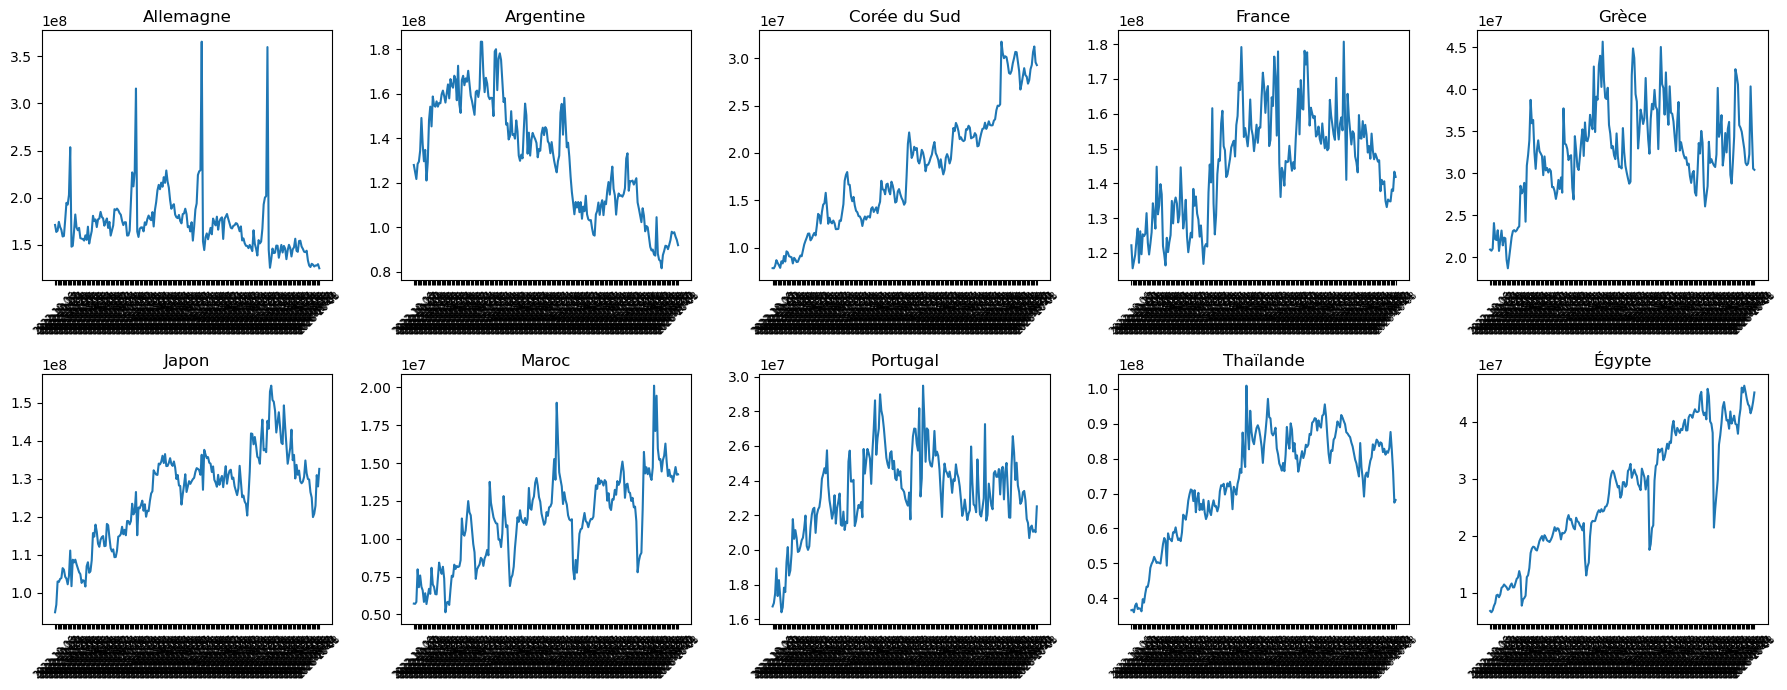

In [29]:
plt.figure(figsize=(18, 7))  # une grande figure pour placer les 10 graphiques
for i in range(10):  # on répète pour chacun des 10 pays
    p = pays_liste[i]  # le pays numéro i
    un_pays = totaux[totaux["pays"] == p]  # on garde seulement les lignes de ce pays
    plt.subplot(2, 5, i + 1)  # 2 lignes et 5 colonnes de graphiques : on dessine dans la case i + 1
    plt.plot(un_pays["semaine"], un_pays["streams"])  # la courbe : les semaines en abscisse, le total des streams en ordonnée
    plt.title(p)  # le nom du pays en titre
    plt.xticks(rotation=45, fontsize=7) ## je penche les dates à 45° et je les écris en petit pour qu'elles ne se chevauchent pas
plt.tight_layout() # j'arrange les 10 graphiques pour que les titres et les dates ne se touchent pas
plt.show()  # on affiche la figure

**Ce que montrent les courbes**

- **Égypte, Corée du Sud** : hausse continue sur toute la période, par paliers. En Égypte, il y a aussi des chutes courtes chaque printemps (mars-avril).
- **Thaïlande, Japon** : hausse jusqu'en 2024 (fin de la hausse début 2024 au Japon, mi-2024 en Thaïlande), puis le total reste à peu près stable ou baisse légèrement.
- **Maroc** : hausse en 2023, puis le total devient très irrégulier, avec de gros pics fin 2024 et début 2026.
- **France, Portugal, Grèce** : hausse jusqu'à un niveau haut en 2024, puis baisse : dès 2024 au Portugal, à partir de mi-2025 en France. En Grèce, le total varie beaucoup en 2025-2026, avec une légère baisse.
- **Argentine** : niveau haut pendant tout 2023, puis baisse continue depuis début 2024, avec une chute nette début 2025.
- **Allemagne** : niveau assez plat (petite bosse mi-2024), qui baisse en 2025-2026, avec un pic très haut chaque fin décembre (probablement les chansons de Noël, à vérifier en 3.1.3).

In [38]:
debut = totaux.groupby("pays").head(4).groupby("pays")["streams"].mean()  # pour chaque pays, moyenne des 4 premières semaines (octobre 2022)
fin = totaux.groupby("pays").tail(4).groupby("pays")["streams"].mean()  # pour chaque pays, moyenne des 4 dernières semaines (octobre 2026)

variation = (fin - debut) / debut * 100  # évolution en % entre le début et la fin

resultat = pd.DataFrame({"debut": debut, "fin": fin, "variation_%": variation.round(1)})  # on réunit les trois résultats dans un tableau (variation arrondie à 1 chiffre après la virgule)
print(resultat)  # on affiche le tableau

                     debut           fin  variation_%
pays                                                 
Allemagne     1.685546e+08  1.277431e+08        -24.2
Argentine     1.257255e+08  9.492123e+07        -24.5
Corée du Sud  8.118571e+06  3.017595e+07        271.7
France        1.186938e+08  1.403080e+08         18.2
Grèce         2.168234e+07  3.408876e+07         57.2
Japon         9.940037e+07  1.286121e+08         29.4
Maroc         6.299530e+06  1.437164e+07        128.1
Portugal      1.752690e+07  2.143008e+07         22.3
Thaïlande     3.673130e+07  7.358771e+07        100.3
Égypte        7.036186e+06  4.307063e+07        512.1


**Ce que montre le tableau**

Le tableau compare la moyenne des 4 premières semaines (octobre 2022) à celle des 4 dernières (octobre 2026). Comme les deux périodes tombent en octobre, la saison ne fausse pas la comparaison.

- **8 pays sur 10 sont en hausse.** Les plus fortes : Égypte (+512 %), Corée (+272 %), Maroc (+128 %) et Thaïlande (+100 %). Plus faibles : Grèce (+57 %), Japon (+29 %), Portugal (+22 %), France (+18 %).
- **2 pays sont en baisse** : Argentine (−24,5 %) et Allemagne (−24,2 %).
- Le tableau précise ce que les courbes ne montrent pas bien : l'Allemagne est en baisse, ce que les pics de Noël cachaient. À l'inverse, la France, le Portugal et la Grèce restent au-dessus de leur niveau de 2022, malgré leur baisse récente.

## 3.2. RENOUVELLEMENT DES CLASSEMENTS

Cette section étudie le renouvellement du top 200 à travers trois indicateurs : le nombre de titres différents, les nouvelles entrées par semaine et la durée de présence des titres, les entrées étant distinguées entre nouveautés et ré-entrées. L’hypothèse retenue est que ***plus les entrées hebdomadaires sont nombreuses, plus le renouvellement du classement est rapide.*** *Sa vérification permet de distinguer les marchés ouverts aux nouveaux titres de ceux dominés par des titres durablement installés.*

### 3.2.1. Titres distincts par pays sur la période 

Le premier indicateur mesure le nombre de titres différents ayant figuré dans le top 200 d’un pays au cours des 210 semaines. Plus ce nombre est élevé, plus le classement accueille de titres différents.

In [39]:
res=base.groupby("pays")["uri"].nunique().to_frame().sort_values("uri", ascending=False).rename(columns={"uri":"titres_distincts"})

# Ligne pour l'ensemble des 10 pays (un titre classé dans plusieurs pays compte une fois)
res.loc["Total (10 pays)"] = [base["uri"].nunique()]

#Affichage
res

,titres_distincts
pays,
Allemagne,5316
France,3693
Grèce,3520
Portugal,2800
Maroc,2774
Corée du Sud,2668
Argentine,2404
Thaïlande,2045
Japon,1848


On constate que le top 200 accueille beaucoup plus de titres différents en Allemagne (5 316) qu’au Japon (1 848) ou en Égypte (1 817). Ainsi, le classement allemand change beaucoup plus que le classement japonais ou égyptien. Cela peut venir d’entrées plus nombreuses chaque semaine, ou de titres qui restent moins longtemps dans le classement. Pour le savoir, **il faut examiner les nouvelles entrées et la durée de présence des titres.**

On constate également que 23 000 titres différents ont été classés dans au moins un des dix pays, contre 28 885 en additionnant les résultats par pays. Cet écart s’explique par le fait que certains titres apparaissent dans plusieurs pays.

### 3.2.2. Nouvelles entrées par semaine

Le deuxième indicateur mesure le nombre moyen de titres qui entrent chaque semaine dans le top 200. On distingue les nouveautés, qui apparaissent pour la première fois, des ré-entrées, qui reviennent après une absence. 

In [31]:
base["previous_rank"].value_counts().sort_index()

previous_rank
-1      42025
 1       2095
 2       2090
 3       2090
 4       2090
        ...  
 196      926
 197      899
 198      899
 199      850
 200      808
Name: count, Length: 201, dtype: int64

In [32]:
base[(base["previous_rank"] == -1)].shape[0]

42025

In [33]:
# Compteur repris à 1 à la première apparition du titre dans la base

"""Nombre de semaines passées par le titre dans le classement du pays depuis son premier passage dans la base. 
Elle vaut 1 à sa première apparition, puis augmente d’une unité par semaine de présence."""

base["weeks_fenetre"] = (base["weeks_on_chart"]
                         - base.groupby(["pays", "uri"])["weeks_on_chart"].transform("min")
                         + 1)

In [34]:
base[(base["previous_rank"] == -1) & (base["weeks_fenetre"] > 1)].shape[0]

17460

In [35]:
base[(base["previous_rank"] == -1) & (base["weeks_fenetre"] == 1)].shape[0]

24565

In [36]:
# Sélection des entrants tout au long de la période
base["entrants"] = base["previous_rank"] == -1 #previous_rank vaut -1 lorsque la chanson n'y était pas la semaine précédente

# Sélection des nouveautés parmi les entrants
base["nouveautes"] = (base["entrants"]) & (base["weeks_fenetre"] == 1)

# Sélection des ré-entrants parmi les entrants
base["re-entrants"] = (base["entrants"]) & (base["weeks_fenetre"] > 1)

In [37]:
# Nombre d'entrées dans chaque classement hebdomadaire
par_sem = (base.groupby(["pays", "semaine"])
               [["entrants", "nouveautes", "re-entrants"]].sum()) # True est représenté comme 1.

par_sem

entrants  nouveautes  re-entrants
pays      semaine                                      
Allemagne 2022-10-06        45          45            0
          2022-10-13        28          28            0
          2022-10-20        23          23            0
          2022-10-27        32          32            0
          2022-11-03        17          13            4
...                        ...         ...          ...
Égypte    2026-09-10        18           7           11
          2026-09-17        14           7            7
          2026-09-24        11           3            8
          2026-10-01        14           6            8
          2026-10-08        10           4            6

[2100 rows x 3 columns]

In [40]:
noms = {"nouveautes": "Nouveautés", "re-entrants": "Ré-entrées"}

# Les 10 pays en un seul tableau de petits graphiques
petits_multiples(par_sem, ["nouveautes", "re-entrants"], noms=noms, ncols=2,
                 titre="Entrées par pays", axe="Titres par semaine");

In [39]:
noms = {"nouveautes": "Nouveautés", "re-entrants": "Ré-entrées"}

fig = barres(par_sem.groupby("pays").mean().round(1), ["nouveautes", "re-entrants"], empiler=True, total="entrants",
             format_val=".1f", noms=noms,
             titre="Entrées moyennes par semaine dans le top 200",
             axe="Titres par semaine")

On constate que l’Allemagne se distingue par le rythme de renouvellement le plus élevé, avec 33,3 entrées par semaine en moyenne, ainsi que par de fortes fluctuations au cours de la période. À l’inverse, le Japon et l’Égypte enregistrent moins d’entrées, avec respectivement 13,6 et 13,2 par semaine, et présentent des évolutions plus stables.

De plus, les nouveautés dominent en Allemagne, en Grèce et en France, tandis que les ré-entrées sont plus nombreuses au Portugal, en Argentine, en Thaïlande et au Japon. Le Maroc et la Corée du Sud présentent des volumes assez proches pour les deux catégories. Ces différences montrent que le renouvellement du classement repose soit sur l’arrivée de nouveaux titres, soit sur le retour de titres déjà présents.

### 3.2.3. Durée de séjour dans le classement

Le troisième indicateur mesure combien de temps les titres restent dans le top 200. Pour chaque titre et chaque pays, on retient la durée totale de présence, donnée par la valeur maximale de weeks_on_chart, afin que chaque titre ne soit compté qu’une fois. On décrit sa distribution par pays : durée moyenne et médiane, part des titres qui ne restent qu’une semaine, et part de ceux qui durent au moins un an.

In [81]:
# Une ligne par titre et par pays
g = (base.groupby(["pays", "uri"])
         .agg(duree=("weeks_fenetre", "max"),          # durée totale du séjour
              nb_semaines=("semaine", "nunique"))       # semaines vues dans la base
         .reset_index())

g

,pays,uri,duree,nb_semaines
0,Allemagne,spotify:track:001TLpmtuQMWJYyE7q9ayM,1,1
1,Allemagne,spotify:track:003vvx7Niy0yvhvHt4a68B,146,146
2,Allemagne,spotify:track:007tCma4anG4nzhE1jzzSd,2,2
3,Allemagne,spotify:track:00FgA8qDMtKrAokzmRrsPH,1,1
4,Allemagne,spotify:track:00XmE56Q9wZ6ztUrCRYW4D,1,1
...,...,...,...,...
28880,Égypte,spotify:track:7yqw4f8ovU2HuuQmfy4kVu,9,9
28881,Égypte,spotify:track:7zCFOXdSE6zkM8rVuEo6Ga,2,2
28882,Égypte,spotify:track:7zE6sykTrQkXMaiZTZJSFJ,5,5
28883,Égypte,spotify:track:7zOLnHG9JUViKeW8DnWzIF,9,9


In [82]:
# Tableau par pays
tab = (g.groupby("pays")["duree"]
        .agg(titres="size", moyenne="mean", mediane="median",
             p90=lambda x: x.quantile(.9),
             pct_1_semaine=lambda x: 100 * (x == 1).mean(),
             pct_52_plus=lambda x: 100 * (x >= 52).mean())
        .round(1)
        .sort_values("mediane", ascending=False))
tab

,titres,moyenne,mediane,p90,pct_1_semaine,pct_52_plus
pays,,,,,,
Égypte,1817,23.1,9.0,62.4,16.5,14.3
Japon,1848,22.9,7.0,62.3,16.1,12.9
Thaïlande,2045,20.6,7.0,61.0,19.0,12.6
Argentine,2404,17.5,6.0,48.0,19.1,9.2
Maroc,2774,15.2,5.0,43.0,25.5,8.3
Corée du Sud,2668,15.8,4.0,46.0,25.6,8.8
Portugal,2800,15.0,4.0,43.1,27.8,8.0
Grèce,3520,11.9,4.0,32.0,28.0,5.1
France,3693,11.4,3.0,31.0,31.1,4.7


On constate que la durée de séjour des titres varie assez d’un pays à l’autre. En Allemagne, la durée médiane est de 2 semaines et 42,8 % des titres ne restent qu’une semaine dans le classement, alors qu’en Égypte la médiane est de 9 semaines et seulement 16,5 % des titres restent une semaine. Le Japon et la Thaïlande ont une médiane de 7 semaines, la France de 3 semaines et la Grèce de 4 semaines.

De plus, la moyenne est nettement supérieure à la médiane dans tous les pays (par exemple 23,1 contre 9 semaines en Égypte). Cela s’explique par un petit nombre de titres qui restent très longtemps : 14,3 % des titres égyptiens et 12,9 % des titres japonais sont classés au moins 52 semaines, contre 3,0 % en Allemagne et 4,7 % en France.

<u>**INFORMATION À RETENIR**</u>

Cette sous-partie portant sur le renouvellement des classements, nous a permis de comprendre que ***plus un pays a enrégistré de titre dans la période considérée, plus le renouvellement est rapide***. *L’Allemagne en est l’exemple extrême : 5 316 titres différents classés sur la période, une durée médiane de présence de 2 semaines et 42,8 % de titres qui ne restent qu’une semaine. À l’opposé, l’Égypte, le Japon et la Thaïlande comptent environ 1 800 à 2 000 titres différents, avec une durée médiane de 7 à 9 semaines et plus de 12 % de titres classés au moins un an.* Ces résultats confirment l’hypothèse de départ.

Ils soulèvent toutefois plusieurs questions, qui seront examinées dans les parties suivantes. 
- **Les trois marchés au renouvellement lent ont en commun une langue et une écriture propres (arabe, japonais, thaï) : : leur stabilité tient-elle à un répertoire local dominant, peu concurrencé par les succès internationaux, du fait de la langue ?**
- **Dans les pays où le classement se renouvelle rapidement (Allemagne, France, Grèce), cela s’explique-t-il par une plus grande présence de titres en langues étrangères, en l’occurrence l’anglais, qui représente 16% des titres classés sur la période ?**
- **Les titres nationaux parviennent-ils à rester dans le classement malgré l’arrivée régulière de nouveaux titres étrangers ?**

## 3.3. CONCENTRATION DU MARCHE

# 4. PREFERENCE NATIONALE, LANGUES ET QUOTAS

## 4.3. MODELE ECONOMETRIQUE

Dans cette partie, trois modèles de régression linéaire seront estimés à partir de la spécification générale suivante :

$$
\log(\text{streams}_{ict}) = \alpha_{it}+\delta_{ct}
+ \beta\,\text{National}_{ic}
+ \gamma\,\text{LangueLocale}_{ic}
+ \varepsilon_{ict}
$$

Les estimations seront réalisées sur trois échantillons :
- l’ensemble des données ;
- les pays appliquant des quotas ;
- les pays n’appliquant pas de quotas.

In [83]:
#DOSSIER = "C:/Users/HP/Desktop/ENSAE/2A/PROJET PYTHON/"
DOSSIER = ""

# 1. Charger les trois fichiers
nat = pd.read_csv(DOSSIER + "artistes_nationalites.csv", keep_default_na=False)
lang = pd.read_csv(DOSSIER + "chansons_langues.csv", keep_default_na=False)

# 4. Ajouter la nationalité (par artiste) et la langue (par artiste et titre)
nb_lignes = len(base)
base = base.merge(nat, on="artist_names", how="left")
base = base.merge(lang, on=["artist_names", "track_name"], how="left")

# 5. Vérifier que le nombre de lignes n'a pas changé
print("Lignes avant :", nb_lignes, "| après :", len(base))

# 6. Cases sans information : vides (et ERREUR traité comme inconnu)
for col in ["nationalite", "langue"]:
    base[col] = base[col].fillna("").replace("ERREUR", "")

# 7. Taux de remplissage
for col in ["nationalite", "langue"]:
    rempli = base[col] != ""
    print(col, ":", round(rempli.mean() * 100, 1), "% des lignes,",
          round(base.loc[rempli, "streams"].sum() / base["streams"].sum() * 100, 1), "% des écoutes")

# 8. Enregistrer
#base.to_csv(DOSSIER + "base_complete_enrichie.csv", index=False)"""

Lignes avant : 419891 | après : 419891
nationalite : 99.9 % des lignes, 99.9 % des écoutes
langue : 100.0 % des lignes, 100.0 % des écoutes


L'objectif est de mesurer deux choses : **les artistes nationaux bénéficient-ils de davantage d'écoutes dans leur pays ? Et les chansons chantées dans la langue locale y sont-elles davantage écoutées ?**

Pour répondre à ces questions, nous comparons les écoutes d'un même titre, au cours d'une même semaine, dans différents pays. Cela permet de mieux isoler le rôle de la nationalité de l'artiste et de la langue de la chanson.

#### 1. Présentation des variables

Chaque observation correspond à un titre $i$, dans un pays $c$, au cours d'une semaine $t$. 

Les variables utilisées dans le modèle sont les suivantes :

- **log(streams)** : représente le nombre d'écoutes du titre, exprimé en logarithme. Les coefficients peuvent ainsi être interprétés approximativement en pourcentage. Pour un coefficient $\beta$, l'écart correspondant est de $(e^\beta-1)\times100$ %.
- **National** : vaut 1 si au moins un artiste du titre est originaire du pays étudié, et 0 sinon. Par exemple, un titre d'Aya Nakamura est considéré comme national en France, mais pas en Allemagne.
- **LangueLocale** : vaut 1 si le titre est chanté dans la langue principale du pays étudié, et 0 sinon.
- **$\alpha_{it}$** : représente l'effet fixe titre-semaine. Il permet de prendre en compte les caractéristiques communes à un même titre au cours d'une même semaine, comme sa popularité, sa promotion ou sa notoriété. Nous pouvons ainsi comparer les écoutes d'un même titre entre différents pays, au même moment.
- **$\delta_{ct}$** : représente l'effet fixe pays-semaine. Il permet de prendre en compte les caractéristiques communes à l'ensemble des titres d'un même pays au cours d'une même semaine, comme la taille du marché, le niveau général d'écoute ou les événements locaux. Les écarts d'écoutes entre pays ne sont ainsi pas attribués à tort à la nationalité ou à la langue.
- **$\beta$ et $\gamma$** : sont les coefficients que nous cherchons à estimer. Le premier mesure l'écart d'écoutes associé à la nationalité de l'artiste, tandis que le second mesure celui associé à la langue locale. Ils sont estimés simultanément afin de distinguer leurs effets respectifs.
- **$\varepsilon$** : représente les autres facteurs qui peuvent expliquer les écarts d'écoutes, mais qui ne sont pas pris en compte dans le modèle.

Les écarts-types sont regroupés par titre, car les observations d'un même titre, d'une semaine et d'un pays à l'autre, ne sont pas indépendantes.

#### 2. Choix des effets fixes

Une spécification plus simple aurait consisté à introduire un effet fixe titre et un effet fixe pays, sans dimension temporelle. Nous ne la retenons pas comme spécification principale, pour deux raisons.

**Le cycle de vie des titres.** Les écoutes d'un titre sont maximales dans les semaines qui suivent sa sortie, puis diminuent. Avec un simple effet fixe titre, les écoutes d'un même titre peuvent être comparées entre un pays où il vient de sortir et un pays où il est classé depuis plusieurs mois. L'écart observé mélange alors l'effet du pays et celui de l'ancienneté du titre. L'effet fixe titre-semaine impose de comparer le même titre au même moment de sa diffusion. Il neutralise également les variations d'écoute communes à tous les pays une semaine donnée, comme une sortie mondiale ou les fêtes de fin d'année.

**L'évolution propre à chaque marché.** L'effet fixe titre-semaine ne peut pas neutraliser ce qui touche un seul pays, puisqu'il prend la même valeur pour un titre dans tous les pays une semaine donnée. Or le nombre d'utilisateurs de Spotify a progressé différemment selon les pays entre 2022 et 2026, et certains événements ne concernent qu'une partie des pays, comme le ramadan en Égypte et au Maroc. Un effet fixe pays, constant sur toute la période, ne prend pas en compte ces variations. L'effet fixe pays-semaine les neutralise, semaine par semaine, sans réduire le nombre d'observations.

Cette spécification a une contrepartie. Seuls les titres classés dans au moins deux pays au cours d'une même semaine contribuent à l'estimation, soit 88 030 observations sur environ 419 000. Les résultats portent donc sur les titres qui circulent entre pays, et non sur l'ensemble des classements.

#### 3. Comparaison des pays avec et sans quotas

Nous estimons ensuite le même modèle sur trois échantillons : l'ensemble des pays, les pays appliquant des quotas et ceux n'en appliquant pas.

Cette comparaison permet de voir si l'avantage associé à la nationalité des artistes ou à la langue locale est différent selon l'existence de quotas.

Si les coefficients sont plus élevés dans les pays appliquant des quotas, cela pourrait indiquer que les artistes nationaux ou les chansons en langue locale y bénéficient d'un avantage plus important.

Toutefois, cette comparaison ne permet pas d'affirmer que les quotas sont directement responsables de ces différences. Les deux groupes de pays diffèrent aussi par leur langue, la taille de leur marché et leur industrie musicale. 

In [84]:
# Les titres absents des fichiers deviennent "" au lieu de NaN
base["nationalite"] = base["nationalite"].fillna("")
base["langue"] = base["langue"].fillna("")

# National : le pays du classement fait-il partie de "FR;BE" ?
code_du_pays = {"Argentine": "AR", "Allemagne": "DE", "Égypte": "EG", "France": "FR",
                "Grèce": "GR", "Japon": "JP", "Corée du Sud": "KR", "Maroc": "MA",
                "Portugal": "PT", "Thaïlande": "TH"}
base["code_pays"] = base["pays"].map(code_du_pays)
base["National"] = [
    int(p in n.split(";")) for p, n in zip(base["code_pays"], base["nationalite"])
]

# LangueLocale : la langue du pays fait-elle partie de "fra, eng" ?
langue_du_pays = {"Argentine": "spa", "Allemagne": "deu", "Égypte": "ara", "France": "fra",
                  "Grèce": "ell", "Japon": "jpn", "Corée du Sud": "kor", "Maroc": "ara",
                  "Portugal": "por", "Thaïlande": "tha"}
base["langue_pays"] = base["pays"].map(langue_du_pays)
base["LangueLocale"] = [
    int(lp in l.split(", ")) for lp, l in zip(base["langue_pays"], base["langue"])
]

In [85]:
base.head()

,rank,uri,artist_names,track_name,source,peak_rank,previous_rank,weeks_on_chart,streams,pays,...,weeks_fenetre,entrants,nouveautes,re-entrants,nationalite,langue,code_pays,National,langue_pays,LangueLocale
0,1,spotify:track:5ww2BF9slyYgNOk37BlC4u,Manuel Turizo,La Bachata,Sony Music Latin/La Industria,1,1,17,4434508,Argentine,...,1,False,False,False,CO,spa,AR,0,spa,1
1,2,spotify:track:2tTmW7RDtMQtBk7m2rYeSw,"Bizarrap, Quevedo","Quevedo: Bzrp Music Sessions, Vol. 52/66",DALE PLAY Records,1,2,14,3793440,Argentine,...,1,False,False,False,AR;ES,spa,AR,1,spa,1
2,3,spotify:track:45dlaEXrXW47TVbrQ4gK7E,"Rei, Callejero Fino",Tu Turrito,DALE PLAY Records,3,3,22,3279246,Argentine,...,1,False,False,False,AR,spa,AR,1,spa,1
3,4,spotify:track:3Ne5uYDFzHEFYAPbaBMIck,Maria Becerra,AUTOMÁTICO,300 Entertainment,4,5,4,2991284,Argentine,...,1,False,False,False,AR,spa,AR,1,spa,1
4,5,spotify:track:53tfEupEzQRtVFOeZvk7xq,ROSALÍA,DESPECHÁ,Columbia,3,4,10,2986606,Argentine,...,1,False,False,False,ES,spa,AR,0,spa,1


#### Étape 1 : construction des variables

In [86]:
# Variable expliquée et identifiants des effets fixes
base["log_streams"] = np.log(base["streams"])
base["titre_semaine"] = base["uri"] + "_" + base["semaine"].astype(str)
base["pays_semaine"] = base["pays"] + "_" + base["semaine"].astype(str)

In [87]:
print(base[["National", "LangueLocale"]].mean()*100)

National        61.847479
LangueLocale    71.376381
dtype: float64


On constate que 61% es chansons sont chantés par des artistes nationaux ou un groupe d'un l'un des artistes est national et 70% sont chantées en langue locale

#### Étape 2 : Robustesse

In [88]:
mA = pf.feols("log_streams ~ National + LangueLocale | titre_semaine + pays_semaine",
              data=base, vcov={"CRV1": "uri"})

mB = pf.feols("log_streams ~ National + LangueLocale | uri + pays_semaine",
              data=base, vcov={"CRV1": "uri"})

mC = pf.feols("log_streams ~ National + LangueLocale | titre_semaine + pays",
              data=base, vcov={"CRV1": "uri"})

mD = pf.feols("log_streams ~ National + LangueLocale | uri + pays",
              data=base, vcov={"CRV1": "uri"})

pf.etable([mA, mB, mC, mD])

GT(_tbl_data=  __index_level_0__ __index_level_1__                      0  \
0              coef          National  0.341*** <br> (0.063)   
1              coef      LangueLocale  0.362*** <br> (0.056)   
2                fe              pays                      -   
3                fe      pays_semaine                      -   
4                fe     titre_semaine                      -   
5                fe               uri                      -   
6             stats      Observations                 88,030   
7             stats                R²                  0.932   

                       1                      2                      3  
0  0.238*** <br> (0.053)  0.366*** <br> (0.072)  0.272*** <br> (0.057)  
1  0.209*** <br> (0.047)  0.316*** <br> (0.063)  0.181*** <br> (0.051)  
2                      -                      -                      -  
3                      -                      -                      -  
4                      -                      -                      -  
5                      -                      -                      -  
6                414,054                 88,030                414,054  
7                  0.906                  0.917                  0.892  , _body=<great_tables._gt_data.Body object at 0x7f92e4a86ee0>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x7f92e353b8f0>, _spanners=Spanners([SpannerInfo(spanner_id='log_streams', spanner_level=1, spanner_label=Html(text='log_streams'), spanner_units=None, spanner_pattern=None, vars=['0', '1', '2', '3'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x7f92e3538650>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x7f92e3538410>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient   (Std. Error)')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x7f92e13d7650>, _formats=[<great_tables._gt_data.FormatInfo object at 0x7f92e3538e30>, <great_tables._gt_data.FormatInfo object at 0x7f92e353bbf0>, <great_tables._gt_data.FormatInfo object at 0x7f92e3538050>, <great_tables._gt_data.FormatInfo object at 0x7f92e353acf0>, <great_tables._gt_data.FormatInfo object at 0x7f92e35392b0>, <great_tables._gt_data.FormatInfo object at 0x7f92e3538e90>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_

Un test de robustesse consiste à estimer à nouveau le modèle en modifiant un choix de méthode, afin de vérifier que les conclusions n'en dépendent pas. Nous comparons ici quatre combinaisons d'effets fixes. Les spécifications avec un effet fixe titre, sans dimension temporelle, mobilisent 414 054 observations, car un titre peut alors être comparé d'un pays à l'autre même lorsqu'il n'y est pas classé la même semaine.

| Effets fixes | (1) Titre × semaine + pays × semaine | (2) Titre + pays × semaine | (3) Titre × semaine + pays | (4) Titre + pays |
|---|---|---|---|---|
| National | 0,341*** (+41 %) | 0,238*** (+27 %) | 0,366*** (+44 %) | 0,272*** (+31 %) |
| LangueLocale | 0,362*** (+44 %) | 0,209*** (+23 %) | 0,316*** (+37 %) | 0,181*** (+20 %) |
| Observations | 88 030 | 414 054 | 88 030 | 414 054 |
| R² | 0,932 | 0,906 | 0,917 | 0,892 |

*Écarts-types regroupés par titre. \*\*\* p < 0,001. La spécification (1) est la spécification principale. Intervalles de confiance à 95 % de la spécification (1) : National [+24 % ; +59 %], LangueLocale [+29 % ; +60 %].*

Remplacer l'effet fixe pays-semaine par un simple effet fixe pays modifie peu les coefficients (colonnes 1 et 3). Les variations d'écoute propres à chaque pays au cours du temps biaisent donc peu les résultats.

En revanche, remplacer l'effet fixe titre-semaine par un simple effet fixe titre réduit nettement les deux coefficients (colonnes 1 et 2, ou 3 et 4). Celui de la nationalité reste dans l'intervalle de confiance de la spécification principale. Celui de la langue locale passe en dessous de sa borne basse. Cette baisse est cohérente avec la limite évoquée plus haut : comparer un titre à des stades différents de son cycle de vie ajoute des écarts sans rapport avec la nationalité ou la langue, ce qui tend à atténuer les coefficients estimés.

Les conclusions **qualitatives** sont donc inchangées : dans toutes les spécifications, les deux effets restent positifs et très significatifs. À titre égal, les auditeurs écoutent davantage les artistes de leur pays et les chansons dans leur langue. L'ampleur de l'effet de la langue apparaît toutefois plus sensible au choix des effets fixes.

#### Étape 3 : Estimation

##### 1. Sur les trois échantillons

In [89]:
pays_quotas = ["France", "Portugal", "Grèce", "Argentine"]    
pays_quota_langue=["France","Grèce"]
pays_quota_nationalite = ["Portugal", "Argentine"]  

base["quota"] = base["pays"].isin(pays_quotas).astype(int)
base["quota_langue"] = base["pays"].isin(pays_quota_langue).astype(int)
base["quota_nationalite"] = base["pays"].isin(pays_quota_nationalite).astype(int)

formule = "log_streams ~ National + LangueLocale | titre_semaine + pays_semaine"

m_tout = pf.feols(formule, data=base, vcov={"CRV1": "uri"})
m_quota = pf.feols(formule, data=base[base["quota"] == 1], vcov={"CRV1": "uri"})
m_sans = pf.feols(formule, data=base[base["quota"] == 0], vcov={"CRV1": "uri"})
m_quota_l = pf.feols(formule, data=base[base["quota_langue"] == 1], vcov={"CRV1": "uri"})
m_quota_n = pf.feols(formule, data=base[base["quota_nationalite"] == 1], vcov={"CRV1": "uri"})

pf.etable([m_tout, m_quota, m_sans, m_quota_l, m_quota_n])

GT(_tbl_data=  __index_level_0__ __index_level_1__                      0  \
0              coef          National  0.341*** <br> (0.063)   
1              coef      LangueLocale  0.362*** <br> (0.056)   
2                fe      pays_semaine                      -   
3                fe     titre_semaine                      -   
4             stats      Observations                 88,030   
5             stats                R²                  0.932   

                       1                      2                    3  \
0     0.115 <br> (0.105)  0.533*** <br> (0.081)  -0.110 <br> (0.243)   
1  0.608*** <br> (0.079)     0.121 <br> (0.081)   0.276 <br> (0.295)   
2                      -                      -                    -   
3                      -                      -                    -   
4                 27,844                 39,728                5,982   
5                  0.936                  0.928                 0.95   

                       4  
0    -0.126 <br> (0.164)  
1  0.756*** <br> (0.095)  
2                      -  
3                      -  
4                  8,388  
5                  0.913  , _body=<great_tables._gt_data.Body object at 0x7f92e08fb390>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(5)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x7f92e34e6090>, _spanners=Spanners([SpannerInfo(spanner_id='log_streams', spanner_level=1, spanner_label=Html(text='log_streams'), spanner_units=None, spanner_pattern=None, vars=['0', '1', '2', '3', '4'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x7f92e34e6b10>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x7f92e34e6210>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient   (Std. Error)')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x7f92df8804d0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x7f92e34e4050>, <great_tables._gt_data.FormatInfo object at 0x7f92e34e45f0>, <great_tables._gt_data.FormatInfo object at 0x7f92e34e75f0>, <great_tables._gt_data.FormatInfo object at 0x7f92e34e6630>, <great_tables._gt_data.FormatInfo object at 0x7f92e8342bd0>, <great_tables._gt_data.FormatInfo object at 0x7f92e8341250>, <great_tables._gt_data.FormatInfo object at 0x7f92e8341370>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px',

Sur l'ensemble des pays (modèle (1)), un même titre réalise, la même semaine, environ 40,6 % d'écoutes supplémentaires ($e^{0,341}-1$) dans un pays où l'un de ses artistes est national, et environ 43,6 % ($e^{0,362}-1$) dans un pays dont il chante la langue principale. Les deux effets sont positifs et statistiquement significatifs.

 En se restreignant aux pays appliquant des quotas, à savoir l'Argentine, la France, la Grèce et le Portugal (modèle (2)), un titre réalise environ 83,7 % d'écoutes supplémentaires lorsqu'il est chanté dans la langue principale du pays. Le coefficient de **National** n'est en revanche pas significatif : les données ne permettent pas de mettre en évidence un avantage propre aux artistes nationaux, une fois la langue prise en compte. Dans les pays sans quotas (modèle (3)), on observe la situation inverse : les titres d'artistes nationaux réalisent environ 70,4 % d'écoutes supplémentaires, sans effet significatif de la langue.

Ce résultat peut surprendre, puisque certains de ces pays imposent des quotas fondés sur la nationalité des artistes (30 % en Argentine et au Portugal) : on pourrait s'attendre à un coefficient de **National** significativement positif. Nous avons donc distingué les pays dont les quotas portent sur la langue (France et Grèce, modèle (4)) de ceux dont les quotas portent sur la nationalité (Argentine et Portugal, modèle (5)).

Dans les pays à quotas de nationalité, le coefficient de **National** reste non significatif, tandis que celui de **LangueLocale** passe de 0,608 à 0,756 : un titre y réalise environ 113 % d'écoutes supplémentaires lorsqu'il est chanté dans la langue locale. Dans les pays à quotas de langue, aucun des deux coefficients n'est significatif.

Avec deux pays seulement, chacun de ces modèles revient à comparer un même titre entre ces deux pays, la même semaine.

- Le modèle (5) compare ainsi l'Argentine et le Portugal. Les titres qu'ils partagent sont souvent chantés en espagnol ou en portugais, par des artistes argentins, latino-américains, portugais ou brésiliens. Un titre hispanophone y est nettement plus écouté en Argentine, un titre lusophone nettement plus écouté au Portugal, quelle que soit la nationalité de l'artiste : c'est la langue, et non la nationalité, qui distingue l'écoute des deux pays.
- Le modèle (4) compare la France et la Grèce. Ces deux pays partagent très peu de titres (5 982 observations seulement), et ces titres sont surtout des succès internationaux en anglais, ni français ni grecs. Les variables National et LangueLocale y varient donc très peu, ce qui explique des estimations très imprécises. L'absence d'effet significatif traduit ici un manque d'information plutôt qu'une absence de préférence.
- Dans les pays sans quotas, les langues sont peu partagées : un titre en japonais, en coréen ou en thaï est presque toujours interprété par un artiste du pays. Le modèle attribue alors l'essentiel de l'avantage à la nationalité.

**Interprétation.** La préférence pour les titres liés au pays est présente partout, mais elle prend une forme linguistique là où une grande langue est partagée avec d'autres pays (espagnol, portugais, français) et une forme nationale là où la langue est propre au pays. Le type de quota ne correspond donc pas à la forme de la préférence observée : même dans les pays imposant des quotas de nationalité, c'est la langue qui compte sur Spotify. Ce constat doit être nuancé. Les quotas portent sur la radio et non sur le streaming, et les estimations par paire de pays reposent sur peu d'observations. Ces résultats ne permettent pas d'établir un effet des quotas, mais suggèrent que la langue partagée structure davantage les écoutes que la nationalité des artistes.

##### 2. Les pays aux classements les plus stables

La partie 3.2 a montré que les classements ne se renouvellent pas au même rythme selon les pays. L'Égypte (13,2 entrées par semaine en moyenne), le Japon (13,6) et la Thaïlande (16,6) ont les classements les plus stables, alors que tous les autres pays dépassent 18 entrées par semaine. Une hypothèse a alors été avancée : un pays qui écoute surtout ses propres artistes dépendrait moins du flux des sorties internationales, et son classement changerait moins vite.

Pour l'examiner, nous estimons le modèle principal séparément sur deux échantillons : les trois pays aux classements les plus stables, d'une part, et les sept autres pays, d'autre part. Si l'hypothèse est juste, l'avantage associé à la nationalité des artistes devrait être plus marqué dans le premier groupe.

In [90]:
pays_stables = ["Égypte", "Japon", "Thaïlande"]       # classements les moins renouvelés (partie 3.2)
base["stable"] = base["pays"].isin(pays_stables).astype(int)

formule = "log_streams ~ National + LangueLocale | titre_semaine + pays_semaine"

m_stables = pf.feols(formule, data=base[base["stable"] == 1], vcov={"CRV1": "uri"})
m_autres = pf.feols(formule, data=base[base["stable"] == 0], vcov={"CRV1": "uri"})

pf.etable([m_tout, m_stables, m_autres])

GT(_tbl_data=  __index_level_0__ __index_level_1__                      0  \
0              coef          National  0.341*** <br> (0.063)   
1              coef      LangueLocale  0.362*** <br> (0.056)   
2                fe      pays_semaine                      -   
3                fe     titre_semaine                      -   
4             stats      Observations                 88,030   
5             stats                R²                  0.932   

                       1                      2  
0  1.248*** <br> (0.218)  0.345*** <br> (0.086)  
1    -0.269 <br> (0.338)  0.508*** <br> (0.067)  
2                      -                      -  
3                      -                      -  
4                  6,896                 63,601  
5                  0.855                  0.947  , _body=<great_tables._gt_data.Body object at 0x7f92e6382580>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x7f92e8343530>, _spanners=Spanners([SpannerInfo(spanner_id='log_streams', spanner_level=1, spanner_label=Html(text='log_streams'), spanner_units=None, spanner_pattern=None, vars=['0', '1', '2'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x7f92e8341130>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x7f92e83437d0>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient   (Std. Error)')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x7f932d2676a0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x7f92e83400b0>, <great_tables._gt_data.FormatInfo object at 0x7f92e83406b0>, <great_tables._gt_data.FormatInfo object at 0x7f92e8341010>, <great_tables._gt_data.FormatInfo object at 0x7f92e34d23f0>, <great_tables._gt_data.FormatInfo object at 0x7f92e34d3890>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='tabl

Dans les trois pays aux classements les plus stables (modèle (2)), un même titre réalise, la même semaine, environ 248 % d'écoutes supplémentaires ($e^{1,248}-1$) dans le pays de son artiste, soit environ 3,5 fois plus. C'est l'avantage associé à la nationalité le plus élevé de toutes les estimations. Le coefficient de **LangueLocale** est négatif mais non significatif, et son écart-type est très élevé (0,338) : aucun effet propre de la langue ne peut être mis en évidence dans ce groupe.

Dans les sept autres pays (modèle (3)), les deux effets sont positifs et significatifs : environ 41,2 % d'écoutes supplémentaires pour un artiste national et 66,2 % pour un titre en langue locale.

**Interprétation.** Ces résultats vont dans le sens de l'hypothèse formulée dans la partie 3.2 : les pays dont les classements se renouvellent le moins sont aussi ceux où l'avantage des artistes nationaux est le plus marqué. 

Il faut toutefois rester prudent dans la distinction entre l'effet de la nationalité et celui de la langue. En effet, l'arabe, le japonais et le thaï sont propres à certains pays de notre échantillon. Les chansons dans ces langues sont donc souvent interprétées par des artistes du pays concerné. La nationalité et la langue sont ainsi souvent associées, ce qui rend difficile l'estimation de leurs effets séparément. Le modèle attribue une partie importante de l'avantage à la nationalité, tandis que le coefficient de la langue devient négatif. Il est donc préférable de considérer leur effet combiné : environ 0,98, soit 166 % d'écoutes supplémentaires, contre 0,85, soit 135 %, dans les autres pays.

Enfin, cette estimation repose sur un nombre limité d'observations (6 896). Seuls les titres présents dans au moins deux de ces trois pays au cours d'une même semaine sont pris en compte. Il s'agit principalement de succès internationaux et de titres de K-pop. Comme pour l'analyse des quotas, ces résultats montrent une association entre préférence nationale et stabilité des classements, mais ne permettent pas d'établir un lien de causalité.

##### 3. La place de l'anglais

In [91]:
base["Anglais"] = base["langue"].str.split(", ").apply(lambda l: "eng" in l).astype(int)


L'anglais occupe une place particulière dans les classements : c'est la première langue en nombre de titres distincts et la seule présente dans les dix pays étudiés comme le montrent les analyses ci-dessous. Il est donc naturel de se demander si le fait d'être chanté en anglais est associé à davantage d'écoutes.

In [92]:
# Chaque chanson une seule fois, puis découpage "fra, eng" -> deux lignes "fra" et "eng"
langues = (base.drop_duplicates("uri")["langue"]
           .loc[lambda s: s != ""]
           .str.split(", ")
           .explode())

print(langues.nunique(), "langues différentes")
print(sorted(langues.unique()))
print(langues.value_counts())          # nombre de chansons par langue

63 langues différentes
['afr', 'ara', 'arz', 'bam', 'bos', 'cat', 'ceb', 'cmn', 'cos', 'deu', 'ell', 'eng', 'est', 'eus', 'fil', 'fin', 'fra', 'frc', 'fro', 'frr', 'gcf', 'gsw', 'hat', 'heb', 'hin', 'hye', 'ind', 'isl', 'ita', 'jpn', 'khm', 'kik', 'kor', 'ksh', 'lav', 'lin', 'lit', 'mam', 'mfe', 'msa', 'mya', 'nld', 'nmg', 'pcm', 'pol', 'por', 'ron', 'rus', 'scn', 'spa', 'sqi', 'srp', 'swe', 'tgl', 'tha', 'tso', 'tur', 'ukr', 'wol', 'xho', 'yor', 'zho', 'zxx']
langue
eng    3848
deu    3263
fra    2930
ara    2907
ell    2899
       ... 
frr       1
mya       1
scn       1
khm       1
fil       1
Name: count, Length: 63, dtype: int64


In [93]:
titres_pays = base.drop_duplicates(["uri", "pays"])[["uri", "pays", "langue"]]
titres_pays = titres_pays[titres_pays["langue"] != ""]
titres_pays["langue"] = titres_pays["langue"].str.split(", ")
titres_pays = titres_pays.explode("langue").reset_index(drop=True)    # ligne corrigée

grandes = ["eng", "deu", "fra", "ell", "ara", "spa", "kor", "jpn", "tha", "por"]
titres_pays["langue"] = titres_pays["langue"].where(titres_pays["langue"].isin(grandes), "autres")

croise = pd.crosstab(titres_pays["langue"], titres_pays["pays"], margins=True, margins_name="Total")
croise = croise.reindex(grandes + ["autres", "Total"])
croise

pays,Allemagne,Argentine,Corée du Sud,France,Grèce,Japon,Maroc,Portugal,Thaïlande,Égypte,Total
langue,,,,,,,,,,,
eng,1882,359,1344,943,656,330,660,1420,669,287,8550
deu,3260,1,0,3,2,0,2,1,0,0,3269
fra,40,5,3,2677,15,0,528,24,1,23,3316
ell,1,24,0,12,2790,7,31,0,0,35,2900
ara,8,1,0,8,9,0,1472,2,0,1454,2954
spa,49,2016,10,85,26,2,87,166,4,6,2451
kor,23,12,1477,13,26,233,52,24,295,17,2172
jpn,1,1,98,3,0,1395,4,1,26,3,1532
tha,0,0,1,0,0,1,0,6,1156,0,1164


In [94]:
base["Anglais_seul"] = (base["langue"] == "eng").astype(int)            # uniquement en anglais
base["Anglais_mixte"] = (base["Anglais"] == 1) & (base["Anglais_seul"] == 0)
base["Anglais_mixte"] = base["Anglais_mixte"].astype(int)               # anglais + autre langue

print(base.drop_duplicates(["uri", "pays"])
          .groupby("pays")[["Anglais_seul", "Anglais_mixte"]].sum())

              Anglais_seul  Anglais_mixte
pays                                     
Allemagne             1851             31
Argentine              334             25
Corée du Sud          1062            282
France                 879             64
Grèce                  620             36
Japon                  217            113
Maroc                  614             46
Portugal              1383             37
Thaïlande              557            112
Égypte                 268             19


**Pourquoi l'anglais n'apparaît pas dans le modèle principal.** Avec l'effet fixe titre-semaine, chaque titre n'est comparé qu'à lui-même, d'un pays à l'autre : le modèle cherche à savoir si un même titre fait plus d'écoutes dans un pays que dans un autre. Une variable ne peut donc avoir un effet mesurable que si elle change d'un pays à l'autre pour un même titre. C'est le cas de National : un titre d'Aya Nakamura est national en France, mais pas en Allemagne. C'est aussi le cas de LangueLocale : un titre en français est en langue locale en France, mais pas en Grèce. Ce n'est en revanche pas le cas de l'anglais. L'anglais n'étant la langue principale d'aucun des dix pays, un titre en anglais l'est partout : « Blinding Lights » est en anglais en France, en Allemagne comme en Égypte. Comparer ce titre à lui-même ne dit donc rien de l'effet de l'anglais, puisque l'anglais est présent des deux côtés de la comparaison. Cet effet ne peut pas être estimé dans le modèle principal.

**Une comparaison différente.** Pour mesurer l'effet de l'anglais, il faut comparer des titres différents, les uns en anglais et les autres non. Nous retirons donc l'effet fixe titre et estimons un modèle complémentaire :

$$\log(\text{streams}_{ict}) = \delta_{ct} + \theta\,\text{Anglais}_{i} + \beta\,\text{National}_{ic} + \gamma\,\text{LangueLocale}_{ic} + \varepsilon_{ict}$$

où **Anglais** vaut 1 si le titre est chanté, au moins en partie, en anglais. L'effet fixe pays-semaine $\delta_{ct}$ permet de comparer les titres au sein d'un même classement hebdomadaire, c'est-à-dire dans le même pays et la même semaine. Dans une seconde version, nous ajoutons un effet fixe artiste, afin de comparer les titres d'un même artiste, les uns en anglais et les autres non. Cette version neutralise la notoriété de l'artiste : les titres en anglais sont souvent ceux de vedettes internationales, dont le succès ne tient pas à la langue. Le modèle est enfin estimé séparément pour les pays avec et sans quotas, ainsi que pour les trois pays aux classements les plus stables présentés dans la section 5.

**Deux précautions.** Ce modèle compare des titres différents et non le même titre d'un pays à l'autre. Il est donc moins rigoureux que le modèle principal, car des différences entre titres autres que la langue peuvent subsister. De plus, la base ne contient que le top 200 : les titres comparés ont tous déjà du succès, et les écarts mesurés ne disent rien de l'effet de l'anglais sur la probabilité d'entrer dans le classement.

**Une piste complémentaire.** Il est possible de conserver l'effet fixe titre en croisant la variable Anglais avec chaque pays. Cette interaction change d'un pays à l'autre pour un même titre et peut donc être estimée. Elle répond toutefois à une autre question : non pas « l'anglais augmente-t-il les écoutes ? », mais « un même titre en anglais est-il relativement plus écouté dans un pays que dans un autre ? ».

In [95]:
base["artiste"] = base["artist_names"].str.split(", ").str[0]

formule_ang = "log_streams ~ Anglais + National + LangueLocale | pays_semaine + artiste"

# Modèle complémentaire sur l'ensemble, puis avec effet fixe artiste
mE1 = pf.feols(formule_ang, data=base, vcov={"CRV1": "uri"})
#mE2 = pf.feols(formule_ang + " + artiste", data=base, vcov={"CRV1": "uri"})

# Même modèle (sans effet fixe artiste) par groupe de pays
mE_quota = pf.feols(formule_ang, data=base[base["quota"] == 1], vcov={"CRV1": "uri"})
mE_sans = pf.feols(formule_ang, data=base[base["quota"] == 0], vcov={"CRV1": "uri"})
mE_stables = pf.feols(formule_ang, data=base[base["stable"] == 1], vcov={"CRV1": "uri"})
mE_Non_stables = pf.feols(formule_ang, data=base[base["stable"] == 0], vcov={"CRV1": "uri"})

pf.etable([mE1, mE_quota, mE_sans, mE_stables, mE_Non_stables])

GT(_tbl_data=  __index_level_0__ __index_level_1__                      0  \
0              coef           Anglais   0.133** <br> (0.041)   
1              coef          National   0.057** <br> (0.019)   
2              coef      LangueLocale  0.122*** <br> (0.023)   
3                fe           artiste                      -   
4                fe      pays_semaine                      -   
5             stats      Observations                419,375   
6             stats                R²                  0.841   

                       1                     2                   3  \
0   0.161** <br> (0.052)   0.138* <br> (0.056)  0.050 <br> (0.125)   
1     0.001 <br> (0.026)  0.089** <br> (0.029)  0.043 <br> (0.054)   
2  0.204*** <br> (0.036)  0.096** <br> (0.032)  0.025 <br> (0.086)   
3                      -                     -                   -   
4                      -                     -                   -   
5                167,733               251,546             125,840   
6                  0.786                 0.862               0.746   

                       4  
0  0.150*** <br> (0.040)  
1   0.061** <br> (0.022)  
2  0.132*** <br> (0.029)  
3                      -  
4                      -  
5                293,492  
6                  0.861  , _body=<great_tables._gt_data.Body object at 0x7f92e7092350>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(5)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x7f92e0da5c70>, _spanners=Spanners([SpannerInfo(spanner_id='log_streams', spanner_level=1, spanner_label=Html(text='log_streams'), spanner_units=None, spanner_pattern=None, vars=['0', '1', '2', '3', '4'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x7f92e6872f90>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x7f92e6870350>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient   (Std. Error)')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x7f932d265a70>, _formats=[<great_tables._gt_data.FormatInfo object at 0x7f92e6872930>, <great_tables._gt_data.FormatInfo object at 0x7f92e6871eb0>, <great_tables._gt_data.FormatInfo object at 0x7f92e0da5e50>, <great_tables._gt_data.FormatInfo object at 0x7f92e0da4170>, <great_tables._gt_data.FormatInfo object at 0x7f92e0da7ef0>, <great_tables._gt_data.FormatInfo object at 0x7f92e0da4110>, <great_tables._gt_data.FormatInfo object at 0x7f92e0da7710>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_ma

Les modèles comparent les chansons d'un même artiste, en rapportant les écoutes de chacune au niveau général de son classement hebdomadaire, c'est-à-dire du pays et de la semaine où elle est classée. Cela permet de voir si la langue d'une chanson est associée à un nombre d'écoutes plus élevé, sans confondre cet effet avec les différences de notoriété entre artistes ni avec les différences de niveau d'écoute entre pays et entre semaines.

Sur l'ensemble des pays (modèle (1)), les titres en anglais réalisent environ 14,2 % d'écoutes supplémentaires ($e^{0,133}-1$) par rapport aux autres titres du même artiste. Les titres en langue locale en réalisent environ 13,0 %, et les titres d'artistes nationaux environ 5,9 %. Ces trois effets sont positifs et statistiquement significatifs. Les deux derniers ne sont toutefois pas comparables à ceux du modèle principal, qui compare un même titre d'un pays à l'autre et non des titres différents d'un même artiste.

L'avantage de l'anglais se retrouve dans les pays avec quotas (17,5 %), dans les pays sans quotas (14,8 %) et dans les sept pays autres que les trois aux classements les plus stables (16,2 %). Dans ces trois pays (modèle (4)), en revanche, aucun coefficient n'est statistiquement significatif. Peu d'artistes y proposent à la fois des chansons en anglais et dans une autre langue, de sorte que le modèle dispose de peu d'information pour mesurer ces différences.

**Comment interpréter l'avantage de l'anglais ?** Pour un même artiste, les chansons en anglais sont un peu plus écoutées que celles dans d'autres langues. Cela ne signifie pas nécessairement que les auditeurs préfèrent l'anglais. Les artistes qui chantent dans plusieurs langues, notamment de nombreux artistes de K-pop, latino-américains et européens, réservent souvent l'anglais à leurs titres destinés au public international, qui peuvent bénéficier d'une promotion plus importante. L'avantage observé peut donc refléter cette stratégie commerciale plutôt qu'un effet propre de la langue. Par ailleurs, la base ne contient que les 200 titres les plus écoutés de chaque pays : l'analyse porte sur des chansons déjà classées et ne permet pas de savoir si chanter en anglais augmente les chances d'entrer dans le classement.

**L'anglais favorise-t-il la diffusion internationale ?** L'analyse de la circulation des titres entre pays apporte un éclairage complémentaire. Parmi les artistes originaires d'un même pays non anglophone, les chansons en anglais ont environ 13,7 points de pourcentage de chances supplémentaires d'être classées dans au moins deux pays. Cet avantage n'est cependant plus significatif lorsque l'on compare uniquement les chansons d'un même artiste : pour un artiste donné, chanter en anglais n'augmente pas significativement les chances d'être classé à l'étranger. La diffusion internationale plus large des titres en anglais semble donc tenir davantage aux caractéristiques des artistes qui choisissent cette langue qu'à la langue elle-même.

# 5. RESSEMBLANCE ENTRE CLASSEMENTS

Comme le montre le tableau présenté dans la section **3.2**, les dix pays étudiés comptabilisent au total 23 000 titres distincts. Toutefois, le cumul des titres distincts recensés dans chaque pays atteint 28 885. Cet écart s'explique par le fait qu'un même titre peut apparaître dans les classements de plusieurs pays. Il existe donc des titres communs, mais également des titres propres à chaque marché.

Cette partie vise à étudier plus précisément les proximités et les différences entre les classements nationaux. Dans un premier temps, nous mesurons leur similarité à travers les titres partagés et la part des écoutes qui leur est consacrée. Nous examinons ensuite si ces proximités permettent de faire apparaître des groupes de pays aux profils musicaux similaires.

## 5.1. SIMILARITES ENTRE LES CLASSEMENTS

Les régressions précédentes portaient sur les titres : à titre égal, un titre est-il davantage écouté dans le pays de son artiste ou de sa langue ? Cette partie adopte le point de vue des classements dans leur ensemble, en mesurant à quel point les classements de deux pays se ressemblent une même semaine. Elle complète la partie 3.2, qui mesurait la stabilité du classement d'un pays au cours du temps : on s'attend à ce que les pays aux classements les plus stables, comme l'Égypte, le Japon et la Thaïlande, soient aussi ceux dont les classements ressemblent le moins à ceux des autres pays.

Cette partie permet ainsi d'évaluer si les pays tendent à écouter les mêmes succès internationaux ou s'ils conservent chacun un répertoire propre. Elle permet aussi d'examiner l'hypothèse H3, selon laquelle les pays qui partagent une langue ont des classements plus proches. Parmi les dix pays étudiés, seuls l'Égypte et le Maroc ont la même langue principale, l'arabe, avec des dialectes toutefois très différents.

In [96]:
lignes = []
pays_liste=sorted(base["pays"].unique())
for semaine, tab in base.groupby("semaine"):
    titres = {p: set(g["uri"]) for p, g in tab.groupby("pays")}
    ecoutes = {p: g.groupby("uri")["streams"].sum() for p, g in tab.groupby("pays")}

    for a, b in combinations(pays_liste, 2):
        if a not in titres or b not in titres:
            continue
        communs = titres[a] & titres[b]
        union = titres[a] | titres[b]

        jaccard = len(communs) / len(union)
        part_a = ecoutes[a][list(communs)].sum() / ecoutes[a].sum()
        part_b = ecoutes[b][list(communs)].sum() / ecoutes[b].sum()

        lignes.append({"semaine": semaine, "pays_a": a, "pays_b": b,
                       "jaccard": jaccard, "part_ecoutes": (part_a + part_b) / 2})

sim = pd.DataFrame(lignes)
print(sim.shape)
print(sim[["jaccard", "part_ecoutes"]].describe().round(3))

(9450, 5)
        jaccard  part_ecoutes
count  9450.000      9450.000
mean      0.035         0.079
std       0.036         0.079
min       0.000         0.000
25%       0.010         0.022
50%       0.023         0.051
75%       0.047         0.110
max       0.250         0.534


In [97]:
# Une ligne par paire de pays : moyenne des deux indices sur toutes les semaines
moy_paires = (sim.groupby(["pays_a", "pays_b"])[["jaccard", "part_ecoutes"]]
                 .mean()
                 .reset_index())

# En pourcentage, plus facile à lire
moy_paires["jaccard"] = (moy_paires["jaccard"] * 100).round(1)
moy_paires["part_ecoutes"] = (moy_paires["part_ecoutes"] * 100).round(1)

# Noms de colonnes clairs, puis tri de la paire la plus semblable à la moins semblable
moy_paires.columns = ["Pays 1", "Pays 2", "Titres communs (%)", "Écoutes vers titres communs (%)"]
moy_paires = moy_paires.sort_values("Écoutes vers titres communs (%)", ascending=False)

moy_paires

,Pays 1,Pays 2,Titres communs (%),Écoutes vers titres communs (%)
6,Allemagne,Portugal,15.7,30.0
22,Corée du Sud,Thaïlande,8.4,25.4
19,Corée du Sud,Japon,8.5,22.8
2,Allemagne,France,10.8,22.3
27,France,Portugal,10.3,20.8
26,France,Maroc,7.0,16.6
14,Argentine,Portugal,5.3,13.0
21,Corée du Sud,Portugal,5.1,11.0
37,Japon,Thaïlande,3.3,10.9
3,Allemagne,Grèce,5.2,10.9


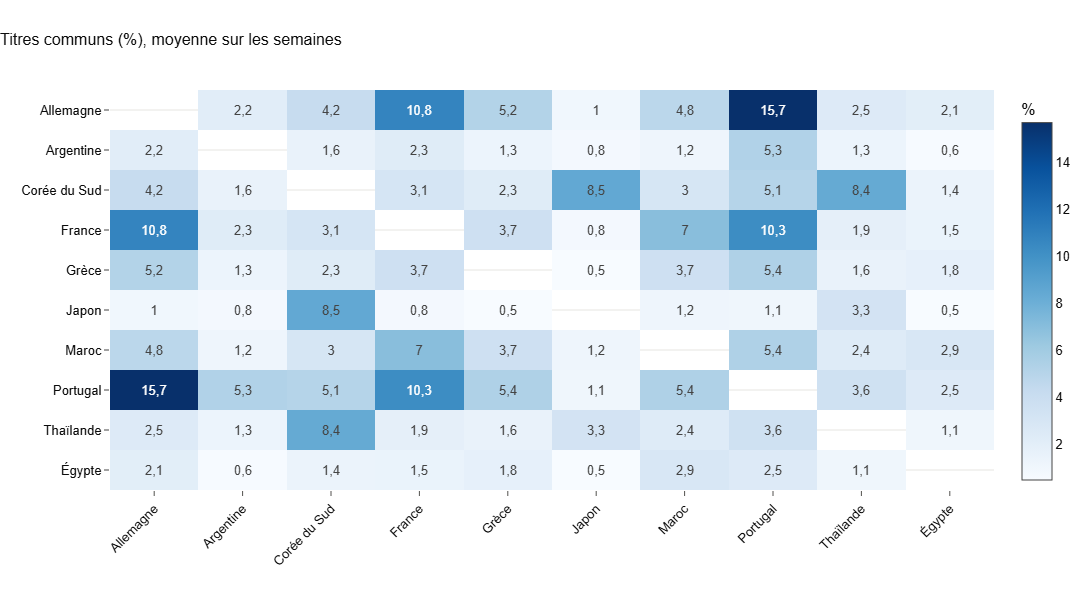

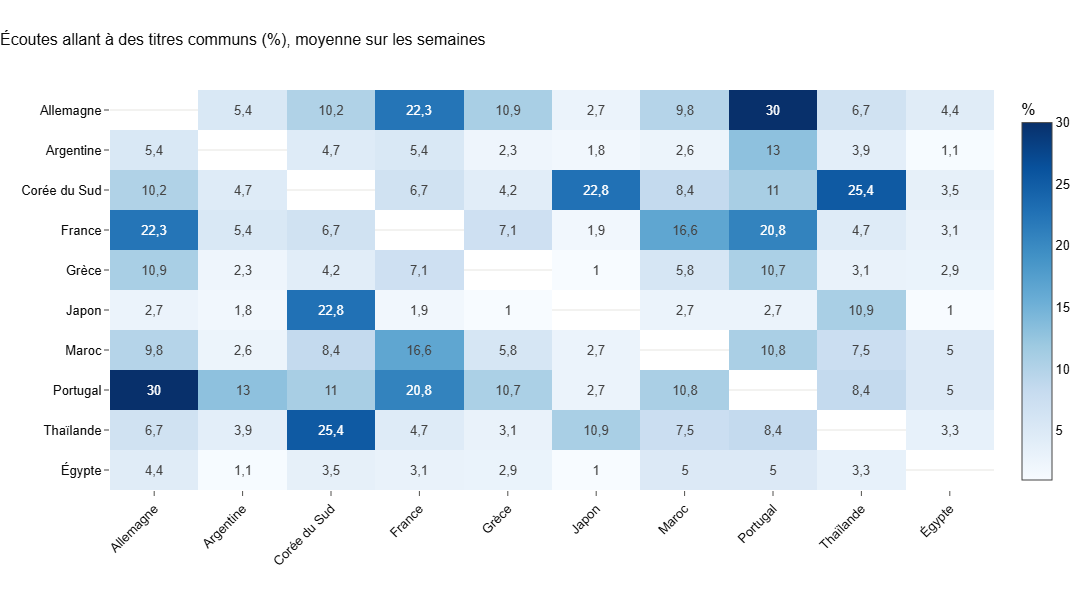

In [98]:
def matrice(indice):
    m = sim.groupby(["pays_a", "pays_b"])[indice].mean().unstack()
    m = m.reindex(index=pays_liste, columns=pays_liste)
    m = m.combine_first(m.T)                 # on recopie la moitié symétrique
    for p in pays_liste:
        m.loc[p, p] = np.nan                 # diagonale vide (un pays face à lui-même)
    return (m * 100).round(1)                # en pourcentage

titres = {"jaccard": "Titres communs (%), moyenne sur les semaines",
          "part_ecoutes": "Écoutes allant à des titres communs (%), moyenne sur les semaines"}

for indice, titre in titres.items():
    fig = px.imshow(matrice(indice), text_auto=True, color_continuous_scale="Blues",
                    labels=dict(color="%"), aspect="auto")
    fig.update_layout(title=titre, xaxis_title="", yaxis_title="",
                      width=750, height=600)
    fig.update_xaxes(side="bottom", tickangle=-45)
    fig.show()

Les classements des dix pays se ressemblent peu : même la paire la plus proche, Allemagne et Portugal, ne partage que 15,7 % de ses titres, et la plupart des paires moins de 5 %. Les titres communs pèsent toutefois environ deux fois plus dans les écoutes que dans le nombre de titres : ce qui circule entre pays, ce sont surtout les grands succès internationaux.

Deux blocs se dégagent : un bloc asiatique autour de la Corée du Sud, liée à la Thaïlande et au Japon par la K-pop, et un bloc européen réunissant l'Allemagne, le Portugal et la France. Le Maroc est nettement plus proche de la France que de l'Égypte, avec laquelle il partage pourtant l'arabe : ce n'est donc pas la langue officielle commune qui rapproche les classements, mais la langue réellement partagée dans la musique, ici le français. Enfin, l'Égypte et le Japon, dont les classements se renouvellent le moins, sont aussi les plus éloignés des autres pays.

**Conclusion.** Les classements des dix pays restent largement distincts : les titres communs sont peu nombreux et se limitent pour l'essentiel aux grands succès internationaux, qui concentrent toutefois une part importante des écoutes partagées. L'écoute sur Spotify ne conduit donc pas à une uniformisation des classements ; chaque pays conserve en grande partie son propre répertoire, ce qui est cohérent avec la préférence pour les artistes nationaux et la langue locale mise en évidence par les régressions.

**L'hypothèse H3** n'est que partiellement confirmée. Le partage d'une langue officielle ne suffit pas à rapprocher deux classements, comme le montre la faible proximité entre l'Égypte et le Maroc. Ce sont plutôt une langue réellement partagée dans la musique, comme le français entre la France et le Maroc, et une circulation régionale des répertoires, comme la K-pop en Asie, qui rapprochent les pays. Ces proximités suggèrent l'existence de groupes de pays aux profils d'écoute voisins, que la classification de la partie 5.2 permet d'identifier plus précisément.

## 5.2. GROUPES DE PAYS

La partie 5.1 a fait apparaître des proximités entre certains pays. Cette partie les systématise au moyen d'une classification ascendante hiérarchique. La distance entre deux pays est définie comme le complément de la part moyenne des écoutes allant à des titres communs : plus deux classements partagent d'écoutes, plus les pays sont proches. Les pays sont ensuite regroupés pas à pas, des plus proches aux plus éloignés, ce qui permet de faire apparaître des groupes de pays aux profils d'écoute voisins.

Étape 1 : Allemagne  +  Portugal  ->  distance 0.700
Étape 2 : Corée du Sud  +  Thaïlande  ->  distance 0.746
Étape 3 : France  +  Allemagne, Portugal  ->  distance 0.784
Étape 4 : Japon  +  Corée du Sud, Thaïlande  ->  distance 0.832
Étape 5 : Maroc  +  France, Allemagne, Portugal  ->  distance 0.876
Étape 6 : Grèce  +  Maroc, France, Allemagne, Portugal  ->  distance 0.914
Étape 7 : Argentine  +  Grèce, Maroc, France, Allemagne, Portugal  ->  distance 0.943
Étape 8 : Japon, Corée du Sud, Thaïlande  +  Argentine, Grèce, Maroc, France, Allemagne, Portugal  ->  distance 0.949
Étape 9 : Égypte  +  Japon, Corée du Sud, Thaïlande, Argentine, Grèce, Maroc, France, Allemagne, Portugal  ->  distance 0.967


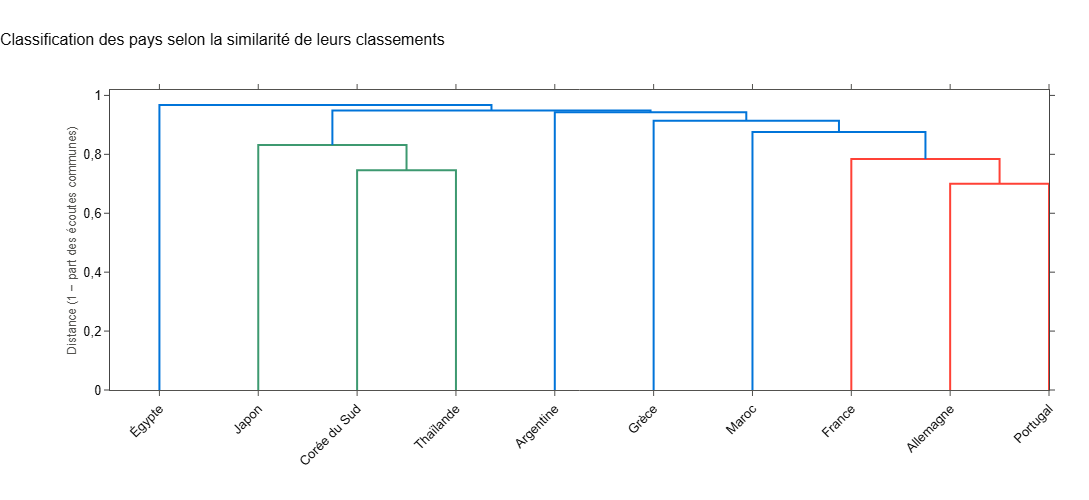

In [99]:
# 1. Matrice de distance : 1 - part moyenne des écoutes allant à des titres communs
sim_ecoutes = matrice("part_ecoutes") / 100
distance = 1-sim_ecoutes.fillna(1)
dist = squareform(distance.to_numpy(), checks=False)
noms = distance.index.tolist()

Z = linkage(dist, method="average")

# On suit les groupes formés à chaque étape pour afficher des noms lisibles
groupes = {i: [nom] for i, nom in enumerate(noms)}
for etape, (g1, g2, hauteur, taille) in enumerate(Z, start=1):
    g1, g2 = int(g1), int(g2)
    nouveau = groupes[g1] + groupes[g2]
    groupes[len(noms) + etape - 1] = nouveau
    print(f"Étape {etape} : {', '.join(groupes[g1])}  +  {', '.join(groupes[g2])}"
          f"  ->  distance {hauteur:.3f}")

# 2. Dendrogramme Plotly, avec nos distances et la méthode de la moyenne
fig = ff.create_dendrogram(
    distance.to_numpy(),
    labels=noms,
    distfun=lambda x: dist,                                # on fournit nos propres distances
    linkagefun=lambda d: linkage(d, method="average"),     # même méthode qu'avant
    color_threshold=0.85,                                  # hauteur de coupe pour colorer les groupes
)
fig.update_layout(title="Classification des pays selon la similarité de leurs classements",
                  yaxis_title="Distance (1 − part des écoutes communes)",
                  width=850, height=500)
fig.update_xaxes(tickangle=-45)
fig.show()

In [100]:
(dist.max()-dist.min())*(dist.max()+dist.min())

np.float64(0.49010000000000004)

Le dendrogramme fait apparaître deux groupes principaux :

- **Groupe européen :** l'Allemagne et le Portugal sont les pays les plus proches (0,700), suivis de la France (0,784). Le Maroc rejoint ensuite ce groupe (0,876), notamment grâce aux liens musicaux avec la France.
- **Groupe asiatique :** la Corée du Sud et la Thaïlande sont proches (0,746), puis le Japon les rejoint (0,832), probablement grâce à la diffusion de la K-pop.

La Grèce et l'Argentine restent plus éloignées du groupe européen. L'Égypte est le pays le plus isolé : elle rejoint les autres en dernier (0,967). Leurs classements sont donc moins proches de ceux des autres pays.



Ces résultats montrent que les ressemblances entre classements suivent davantage des liens musicaux régionaux que le simple partage d'une langue. Par exemple, le Maroc se rapproche du groupe européen bien avant l'Égypte, alors que les deux pays partagent l'arabe.

Cependant, les distances restent élevées (au moins 0,70). Même les pays d'un même groupe partagent donc une part limitée de leurs écoutes. Les préférences musicales restent largement nationales.

**Conclusion.** Les classements des dix pays restent largement nationaux, et leurs ressemblances suivent des logiques régionales, avec un bloc européen et un bloc asiatique, plutôt qu'une langue officielle commune. L'écoute sur Spotify ne conduit donc pas à une uniformisation des goûts, mais à la coexistence de répertoires nationaux et de quelques circulations régionales.